# Trait cross-reference: persona-lsh's trait directions against the HEXACO factor directions

Both studies read the same models' hidden states. persona-lsh gives one direction per behavioral trait (evil,
sycophantic, hallucinating, optimistic, impolite, apathetic, humorous): the mean of *with persona minus without*
over the questions that elicited it. persona-hexaco gives one direction per personality factor (O, C, E, A, N,
H): the direction the model's own inventory answers vary along, from the train half of the items. This notebook
puts them in one space, per model, at one layer.

| Section | Question |
|---|---|
| 1 | Which runs are in both experiments, with the same checkpoint and the same layer count? Which projection seed does each model get? |
| 2 | **Cosine matrix**: how does each trait direction sit against each factor direction, against a permutation null? |
| 3 | **Priors**: do the signs match what the human literature predicts (evil = low H and low A, ...)? |
| 4 | **Across models**: is the trait-by-factor pattern the same in every model? |
| 5 | **Transfer**: does projecting the held-out inventory answers on a *trait* direction predict the keyed rating? |
| 6 | **Prompts**: which way do the differential prompts (DAN, INFO) lean, in trait terms? |
| 7 | **RP-LSH**: does the cosine matrix survive hashing, with the model-derived seed and several plusRand replicates? |
| 8 | **Layer sweep**: where in depth is the cross-reference strongest? |

**Does this need the same seed in both experiments? No.** Cosine geometry has no seed in it: generation is greedy
in both, and each experiment's seed only picks questions (persona-lsh's `rand40` draw) or the train/eval cut
(persona-hexaco). Different draws are fine; the HEXACO directions use the train half only, and section 5 tests on
the eval half. What must match, and section 1 checks:
- the **checkpoint** (same repo; on the rig, the same fingerprint from `lsh.seed`),
- the **layer** (the same depth rule for both) and the **vector kind** (`response` means in both; `prompt` is
  also available on the HEXACO side),
- dtype and transformers version (recorded in each `run_info.json`),
- and, for digests only, the **projection seed**. Section 7 derives it from the model (`lsh.seed`): a hash of the
  model's full HF metadata, salted with the project's common salt, plus a plusRand offset.

Raw states don't leave the rig. This notebook loads them read-only and writes only tables of cosines and
correlations to `<hexaco experiment>/results/crossref/`.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import LinearSegmentedColormap

PERSONA_LSH = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lsh" / "rp_backend.py").is_file())
sys.path.insert(0, str(PERSONA_LSH))
import personality.hexaco as hx
from lsh import RandomProjectionBackend
from lsh import seed as lsh_seed

LSH_ROOT = Path(os.environ.get("PERSONA_LSH_OUTPUT", Path.home() / "persona-lsh-output"))
LSH_EXPERIMENT = "rand40"     # a directory under LSH_ROOT ("" = the published 2026-11-15 run at the root)
HEX_ROOT = Path(os.environ.get("PERSONA_HEXACO_OUTPUT", Path.home() / "persona-hexaco-output"))
HEX_EXPERIMENT = "latest"     # a directory under HEX_ROOT, or "latest"
ONLY = []                     # run names; empty = every run in both

KIND = "response"             # HEXACO vector to compare: "response" matches persona-lsh's; "prompt" is pre-reply
LAYER_DEPTH = 20 / 28         # persona-lsh's default depth, as a share of the layers; same rule on both sides
PERMUTATIONS, PERM_SEED = 500, 0
ALPHA = 0.01                  # permutation p below this marks a cell (min p is 1 / (PERMUTATIONS + 1))
RP_BITS = [256, 1024]
PLUS_RAND = 0                 # offset added to each model's base seed (0 = the model's seed under the salt)
REPLICATES = 5                # projections per model for section 7: PLUS_RAND, PLUS_RAND + 1, ...
SALT = None                   # None: $PERSONA_LSH_SALT or ~/.config/persona-lsh/salt; "" = public, unsalted
SEED_SCOPE = "full"           # "full": every file in the HF snapshot; "weights": weights, config, tokenizer only
FALLBACK_SEED = 42            # when the HF cache isn't here (off the rig): persona-lsh's old fixed seed
SAVE_FIGS = True

# Priors from the personality literature, as (trait, factor): expected sign. Sycophancy is flattery and
# ingratiation, which HEXACO puts at low Sincerity (H) with high Agreeableness; evil is the dark-triad corner, low
# H and low A; impolite is low A; apathetic low E and C; optimistic high E and low N; humorous high E and O.
# hallucinating has no clear prior and is left exploratory.
PRIORS = {("evil", "H"): -1, ("evil", "A"): -1, ("sycophantic", "H"): -1, ("sycophantic", "A"): +1,
          ("impolite", "A"): -1, ("apathetic", "E"): -1, ("apathetic", "C"): -1, ("optimistic", "E"): +1,
          ("optimistic", "N"): -1, ("humorous", "E"): +1, ("humorous", "O"): +1}

pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_rows", 200)
SEQ_DIV = LinearSegmentedColormap.from_list("div", ["#104281", "#5598e7", "#f0efec", "#ec8a89", "#a52a29"])
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 9,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})


def show(df, index=False):
    print(df.to_string(index=index, float_format=lambda v: f"{v:+.2f}"))


def heat(ax, table, vmax, fmt=lambda v: f"{v:+.2f}", marks=None):
    values = table.to_numpy(dtype=float)
    ax.imshow(np.ma.masked_invalid(values), cmap=SEQ_DIV, vmin=-vmax, vmax=vmax, aspect="auto")
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if np.isfinite(values[i, j]):
                star = "*" if marks is not None and bool(marks.iat[i, j]) else ""
                ax.text(j, i, fmt(values[i, j]) + star, ha="center", va="center", fontsize=7,
                        color="white" if abs(values[i, j]) > 0.6 * vmax else "#0b0b0b")
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.grid(False)

## 1. Load both experiments, match runs, derive seeds

A run is used when it's finished in both experiments, both name the same HF repo, and both have the same number
of layers and hidden size. persona-lsh's trait directions use every eliciting question (test and eval
splits; the trait means aren't being classified here) and only the traits `kept_traits.json` kept for that run.

In [2]:
LSH_DIR = LSH_ROOT / LSH_EXPERIMENT if LSH_EXPERIMENT else LSH_ROOT
if HEX_EXPERIMENT == "latest":
    found = sorted(HEX_ROOT.glob("*/experiment.json"), key=lambda p: p.stat().st_mtime)
    assert found, f"no HEXACO experiment under {HEX_ROOT}"
    HEX_DIR = found[-1].parent
else:
    HEX_DIR = HEX_ROOT / HEX_EXPERIMENT
OUT = HEX_DIR / "results" / "crossref"
OUT.mkdir(parents=True, exist_ok=True)

DESIGN = json.loads((HEX_DIR / "experiment.json").read_text())
ITEMS = hx.items_from_records(json.loads((HEX_DIR / "items.json").read_text()))
SPLIT = json.loads((HEX_DIR / "selection.json").read_text())["factors"]
CONDITIONS = [c for c in hx.conditions() if c in DESIGN["prompts"]]
BASE = CONDITIONS.index(DESIGN["baseline"])
FACTORS = list(SPLIT)
INDEX = {item.id: k for k, item in enumerate(ITEMS)}
TRAIN = {f: np.array([INDEX[i] for i in SPLIT[f]["train"]]) for f in FACTORS}
EVAL = {f: np.array([INDEX[i] for i in SPLIT[f]["eval"]]) for f in FACTORS}
KEPT = json.loads((LSH_DIR / "kept_traits.json").read_text())["runs"]


def hex_finished(name):
    d = HEX_DIR / name
    return ((d / "ratings.json").exists() and all(c in json.loads((d / "ratings.json").read_text()) for c in CONDITIONS)
            and all((d / f"states_{c}.pt").exists() for c in CONDITIONS))


def lsh_finished(name):
    d = LSH_DIR / name
    return name in KEPT and all((d / f"all_{t}_diffs.pt").exists() for t in KEPT[name]["kept"])


hex_runs = {p.name for p in HEX_DIR.iterdir() if p.is_dir() and p.name != "results" and hex_finished(p.name)}
lsh_runs = {p.name for p in LSH_DIR.iterdir() if p.is_dir() and lsh_finished(p.name)}
RUNS, rows = [], []
for name in sorted(hex_runs | lsh_runs):
    if ONLY and name not in ONLY:
        continue
    row = {"run": name, "in hexaco": name in hex_runs, "in persona-lsh": name in lsh_runs}
    if name in hex_runs and name in lsh_runs:
        hi = json.loads((HEX_DIR / name / "run_info.json").read_text())
        li = json.loads((LSH_DIR / name / "run_info.json").read_text())
        row |= {"repo": hi.get("repo"), "same repo": hi.get("repo") == li.get("repo"),
                "dtype": f"{li.get('dtype')} / {hi.get('dtype')}",
                "transformers": f"{li.get('transformers')} / {hi.get('transformers')}",
                "lsh tokens": li.get("max_new_tokens"), "hexaco tokens": hi.get("max_new_tokens")}
        if row["same repo"]:
            RUNS.append(name)
    rows.append(row)
print("persona-lsh:", LSH_DIR, "| hexaco:", HEX_DIR)
show(pd.DataFrame(rows))
assert RUNS, "no run is finished in both experiments"
REPO = {n: json.loads((HEX_DIR / n / "run_info.json").read_text())["repo"] for n in RUNS}
print("\nruns compared:", RUNS)

persona-lsh: /home/jo5iah/persona-lsh-output/rand40 | hexaco: /home/jo5iah/persona-hexaco-output/hexaco136-t256-s26988506
             run  in hexaco  in persona-lsh                                     repo same repo             dtype    transformers  lsh tokens  hexaco tokens
        bolt-e4b       True            True nvidia/NVIDIA-Nemotron-3.5-Bolt-E4B-BF16      True float16 / float16 5.23.0 / 5.23.0     +120.00        +256.00
   granite4.2-8b       True            True               ibm-granite/granite-4.2-8b      True float16 / float16 5.23.0 / 5.23.0     +120.00        +256.00
     llama3.1-8b       True            True         meta-llama/Llama-3.1-8B-Instruct      True float16 / float16 5.23.0 / 5.23.0     +120.00        +256.00
nemotron-nano-8b       True            True     nvidia/Llama-3.1-Nemotron-Nano-8B-v1      True float16 / float16 5.23.0 / 5.23.0     +120.00        +256.00
      qwen2.5-7b      False            True                                      NaN       NaN    

In [3]:
# Projection seeds: the model's fingerprint (its full HF metadata), salted with the project's common salt,
# plus PLUS_RAND. Off the rig the HF cache isn't here and every model falls back to FALLBACK_SEED.
SEEDS, rows = {}, []
salt = lsh_seed.load_salt(SALT)
for name in RUNS:
    try:
        from huggingface_hub import snapshot_download
        snap = snapshot_download(REPO[name], local_files_only=True)
        info = lsh_seed.model_seed(snap, plus_rand=PLUS_RAND, scope=SEED_SCOPE, salt=salt)
    except Exception as exc:
        info = {"repo": REPO[name], "fingerprint": None, "salt id": None, "base": FALLBACK_SEED,
                "plus_rand": PLUS_RAND, "seed": lsh_seed.projection_seed(FALLBACK_SEED, PLUS_RAND),
                "note": f"fallback ({type(exc).__name__})"}
    SEEDS[name] = info
    rows.append({"run": name, "fingerprint": (info["fingerprint"] or "")[:16], "salt id": info.get("salt id"),
                 "plus_rand": info["plus_rand"], "seed": info["seed"], "note": info.get("note", "")})
show(pd.DataFrame(rows))
# The record keeps the fingerprint and salt id, not the salt; with a salt, the base seed is secret too.
(OUT / "seeds.json").write_text(json.dumps({n: {k: v for k, v in s.items() if k != "base" or not salt}
                                            for n, s in SEEDS.items()}, indent=1))

             run      fingerprint salt id  plus_rand       seed note
        bolt-e4b 40562ab543500106    none          0 1472685237     
   granite4.2-8b ba92c1e480fc433a    none          0  666309221     
     llama3.1-8b d3e10b8cbb0ab78b    none          0 3912625235     
nemotron-nano-8b 99a5ea16b7b1df9f    none          0 3521749214     
        qwen3-8b 71928e40c422a2b6    none          0 2822511704     


1517

### Directions

- **Trait** (persona-lsh): the mean of the eliciting questions' `with - without` vectors at the layer, as a unit
  vector. It points toward the trait.
- **Factor** (persona-hexaco, `KIND` vectors): persona-hexaco-results section 6's direction. Every rated answer to
  a train item of the factor, under all nine prompts, centered on its prompt's mean over those items, weighted by
  its keyed rating minus the mean keyed rating. It points toward more of the factor (5 = most).
- **Agreement** (control): the same over every factor's train items with the raw rating, so it points toward
  "agree". A trait that lines up with every factor the same way is probably lining up with this.

In [4]:
def layer_of(n_layers):
    return max(1, round(n_layers * LAYER_DEPTH))


def unit(v):
    v = np.asarray(v, dtype=np.float64)
    return v / max(np.linalg.norm(v), 1e-12)


def lsh_stack(name):
    # {trait: [eliciting questions, layers+1, hidden] float32}
    elic = json.loads((LSH_DIR / name / "eliciting_questions.json").read_text())
    out = {}
    for t in KEPT[name]["kept"]:
        d = torch.load(LSH_DIR / name / f"all_{t}_diffs.pt", map_location="cpu").float().numpy()
        rows = [i for i in elic.get(t, []) if i < len(d)]
        if rows:
            out[t] = d[rows]
    return out


def hex_stack(name, kind):
    # (states [conditions, items, layers+1, hidden], raw ratings [conditions, items], keyed [conditions, items])
    states = np.stack([torch.load(HEX_DIR / name / f"states_{c}.pt", map_location="cpu")[kind].float().numpy()
                       for c in CONDITIONS])
    ratings = json.loads((HEX_DIR / name / "ratings.json").read_text())
    raw = np.full((len(CONDITIONS), len(ITEMS)), np.nan)
    for ci, c in enumerate(CONDITIONS):
        for r in ratings[c]:
            if type(r["rating"]) is int and 1 <= r["rating"] <= 5:
                raw[ci, INDEX[r["item"]]] = r["rating"]
    rev = np.array([i.reverse for i in ITEMS])
    return states, raw, np.where(rev, 6 - raw, raw)


def answers(X, values, items):
    # Every usable answer among `items`, centered on its condition's mean over them: (vectors, values, item ids).
    xs, ys, ids = [], [], []
    for c in range(X.shape[0]):
        use = items[np.isfinite(values[c][items]) & np.isfinite(X[c][items]).all(-1)]
        if len(use):
            xs.append(X[c][use] - X[c][use].mean(0))
            ys.append(values[c][use])
            ids.append(use)
    if not xs:
        return np.zeros((0, X.shape[-1])), np.zeros(0), np.zeros(0, dtype=int)
    return np.concatenate(xs), np.concatenate(ys), np.concatenate(ids)


def factor_directions(X, raw, keyed):
    # ({factor: unit direction}, agreement unit direction) from the train half; X = [conditions, items, hidden].
    dirs = {}
    for f in FACTORS:
        d = hx.covariance_direction(*answers(X, keyed, TRAIN[f])[:2])
        if d is not None:
            dirs[f] = unit(d)
    all_train = np.concatenate(list(TRAIN.values()))
    agree = hx.covariance_direction(*answers(X, raw, all_train)[:2])
    return dirs, (unit(agree) if agree is not None else None)


LSH, HEX, LAYERS = {}, {}, {}
for name in RUNS:
    LSH[name] = lsh_stack(name)
    HEX[name] = hex_stack(name, KIND)
    n_lsh, n_hex = next(iter(LSH[name].values())).shape[1] - 1, HEX[name][0].shape[2] - 1
    assert n_lsh == n_hex, f"{name}: {n_lsh} layers in persona-lsh, {n_hex} in hexaco"
    assert next(iter(LSH[name].values())).shape[2] == HEX[name][0].shape[3], f"{name}: hidden sizes differ"
    LAYERS[name] = n_hex


def directions_at(name, layer):
    traits = {t: unit(v[:, layer].mean(0)) for t, v in LSH[name].items()}
    X, raw, keyed = HEX[name]
    factors, agree = factor_directions(X[:, :, layer], raw, keyed)
    return traits, factors, agree


DIRS = {n: directions_at(n, layer_of(LAYERS[n])) for n in RUNS}
for n in RUNS:
    t, f, _ = DIRS[n]
    print(f"{n}: layer {layer_of(LAYERS[n])} of {LAYERS[n]}, traits {list(t)}, factors {list(f)}, "
          f"eliciting per trait {[len(v) for v in LSH[n].values()]}")

bolt-e4b: layer 30 of 42, traits ['evil', 'hallucinating', 'sycophantic', 'apathetic', 'humorous', 'impolite', 'optimistic'], factors ['O', 'C', 'E', 'A', 'N', 'H'], eliciting per trait [22, 24, 34, 38, 40, 27, 40]
granite4.2-8b: layer 29 of 40, traits ['sycophantic', 'apathetic', 'humorous', 'impolite', 'optimistic'], factors ['O', 'C', 'E', 'A', 'N', 'H'], eliciting per trait [19, 25, 13, 15, 26]
llama3.1-8b: layer 23 of 32, traits ['evil', 'hallucinating', 'sycophantic', 'apathetic', 'humorous', 'impolite', 'optimistic'], factors ['O', 'C', 'E', 'A', 'N', 'H'], eliciting per trait [30, 14, 30, 26, 40, 19, 32]
nemotron-nano-8b: layer 23 of 32, traits ['evil', 'humorous', 'optimistic'], factors ['O', 'C', 'E', 'A', 'N', 'H'], eliciting per trait [19, 29, 28]
qwen3-8b: layer 26 of 36, traits ['evil', 'hallucinating', 'sycophantic', 'apathetic', 'humorous', 'impolite', 'optimistic'], factors ['O', 'C', 'E', 'A', 'N', 'H'], eliciting per trait [18, 23, 20, 13, 39, 14, 37]


## 2. Cosine matrix, with a permutation null

Per model, the cosine between every trait direction and every factor direction. Two random directions in a few
thousand dimensions have cosines near 0 (SD about 1/sqrt(hidden), 0.016 at 4096), but these directions aren't
random: both come from the same activation space, which has a few dominant axes. So the null is a **permutation**:
shuffle the keyed ratings among each prompt's train answers of the factor, rebuild the factor direction, and take
its cosine with the trait. That asks whether the *ratings* put the factor direction near the trait, or whether
any weighting of the same answers would (the answers' own main axis). The null is often bimodal (a shuffled
direction still lands on that main axis, with a random sign), so a z-score misleads; `p` is the permutation
p-value of |cosine|, with add-one smoothing, and `*` marks p < `ALPHA`. There are up to 42 cells per model.

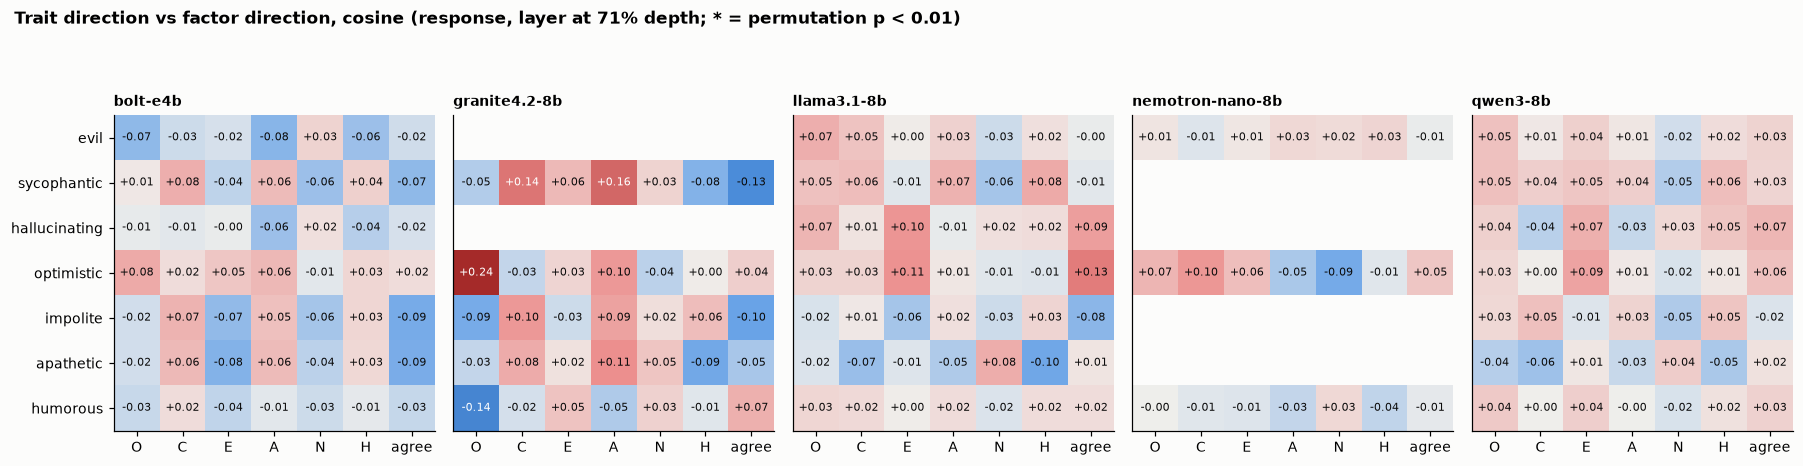

mean over runs (cosine), and how many runs have permutation p < 0.01:

factor            O     C     E     A     N     H
trait                                            
evil          +0.02 +0.00 +0.01 -0.00 +0.00 +0.00
sycophantic   +0.02 +0.08 +0.01 +0.08 -0.03 +0.02
hallucinating +0.03 -0.01 +0.06 -0.03 +0.02 +0.01
optimistic    +0.09 +0.02 +0.07 +0.03 -0.03 +0.00
impolite      -0.03 +0.06 -0.04 +0.05 -0.03 +0.04
apathetic     -0.03 +0.00 -0.02 +0.02 +0.03 -0.05
humorous      -0.02 +0.00 +0.01 -0.01 +0.00 -0.00

factor         O  C  E  A  N  H
trait                          
evil           0  0  0  0  0  0
sycophantic    0  0  0  0  0  0
hallucinating  0  0  0  0  0  0
optimistic     0  0  0  0  0  0
impolite       0  0  0  0  0  0
apathetic      0  0  0  0  0  0
humorous       0  0  0  0  0  0


In [5]:
rng = np.random.default_rng(PERM_SEED)


def null_factor_dirs(X, keyed, f, n):
    # n factor directions from shuffled ratings (within each condition), as rows of unit vectors.
    x, y, _ = answers(X, keyed, TRAIN[f])
    groups, start = [], 0
    for c in range(X.shape[0]):   # answers() concatenates per condition; recover the blocks
        k = int((np.isfinite(keyed[c][TRAIN[f]]) & np.isfinite(X[c][TRAIN[f]]).all(-1)).sum())
        groups.append(np.arange(start, start + k))
        start += k
    out = []
    for _ in range(n):
        yp = y.copy()
        for g in groups:
            yp[g] = rng.permutation(y[g])
        d = hx.covariance_direction(x, yp)
        if d is not None:
            out.append(unit(d))
    return np.array(out)


rows = []
for name in RUNS:
    layer = layer_of(LAYERS[name])
    traits, factors, agree = DIRS[name]
    X, raw, keyed = HEX[name]
    for f, fd in factors.items():
        null = null_factor_dirs(X[:, :, layer], keyed, f, PERMUTATIONS)
        for t, td in traits.items():
            obs, ns = float(td @ fd), null @ td
            rows.append({"run": name, "trait": t, "factor": f, "cosine": obs,
                         "null sd": float(ns.std()), "z": (obs - ns.mean()) / max(ns.std(), 1e-12),
                         "p": (int((np.abs(ns) >= abs(obs)).sum()) + 1) / (len(ns) + 1)})
    if agree is not None:
        for t, td in traits.items():
            rows.append({"run": name, "trait": t, "factor": "agree", "cosine": float(td @ agree)})
COS = pd.DataFrame(rows)
COS.to_csv(OUT / "cosines.csv", index=False)

TRAITS = [t for t in ["evil", "sycophantic", "hallucinating", "optimistic", "impolite", "apathetic", "humorous"]
          if t in set(COS["trait"])]
COLS = FACTORS + ["agree"]
fig, axes = plt.subplots(1, len(RUNS), figsize=(3.3 * len(RUNS), 0.38 * len(TRAITS) + 1.6), squeeze=False)
vmax = max(0.2, float(COS["cosine"].abs().max()))
for ax, name in zip(axes[0], RUNS):
    mine = COS[COS["run"] == name]
    table = mine.pivot(index="trait", columns="factor", values="cosine").reindex(index=TRAITS, columns=COLS)
    marks = (mine.assign(sig=mine["p"] < ALPHA).pivot(index="trait", columns="factor", values="sig")
             .reindex(index=TRAITS, columns=COLS).fillna(False))
    heat(ax, table, vmax, marks=marks)
    ax.set_title(name, fontsize=9)
    if ax is not axes[0][0]:
        ax.set_yticks([])
fig.suptitle(f"Trait direction vs factor direction, cosine ({KIND}, layer at {LAYER_DEPTH:.0%} depth; * = permutation p < {ALPHA})",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.9))
if SAVE_FIGS:
    fig.savefig(OUT / "2_cosines.png", bbox_inches="tight", dpi=150)
plt.show()

print(f"mean over runs (cosine), and how many runs have permutation p < {ALPHA}:\n")
pooled = COS[COS["factor"] != "agree"].groupby(["trait", "factor"]).agg(
    cosine=("cosine", "mean"), sig=("p", lambda p: int((p < ALPHA).sum()))).reset_index()
show(pooled.pivot(index="trait", columns="factor", values="cosine").reindex(index=TRAITS, columns=FACTORS), index=True)
print()
print(pooled.pivot(index="trait", columns="factor", values="sig").reindex(index=TRAITS, columns=FACTORS).to_string())

## 3. Do the signs match the priors?

The `PRIORS` table (top of the notebook) lists the cells where the human literature predicts a sign. Per model:
how many of those cells have the predicted sign (chance 50% each), and how many are also beyond the null
(p < `ALPHA`). A one-sided sign test over all models' prior cells gives the overall p. Matching signs inside the
null is weak; matching signs beyond it is the claim.

In [6]:
from math import comb

rows = []
for (t, f), sign in PRIORS.items():
    for name in RUNS:
        hit = COS[(COS["run"] == name) & (COS["trait"] == t) & (COS["factor"] == f)]
        if len(hit):
            r = hit.iloc[0]
            rows.append({"run": name, "trait": t, "factor": f, "expected": "+" if sign > 0 else "-",
                         "cosine": r["cosine"], "p": r["p"], "sign ok": bool(np.sign(r["cosine"]) == sign),
                         "sign ok, beyond null": bool(np.sign(r["cosine"]) == sign and r["p"] < ALPHA)})
PRIOR_TABLE = pd.DataFrame(rows)
PRIOR_TABLE.to_csv(OUT / "priors.csv", index=False)
if len(PRIOR_TABLE):
    per = PRIOR_TABLE.groupby("run").agg(cells=("sign ok", "size"), sign_ok=("sign ok", "sum"),
                                         sign_ok_beyond_null=("sign ok, beyond null", "sum")).reset_index()
    show(per)
    n, k = len(PRIOR_TABLE), int(PRIOR_TABLE["sign ok"].sum())
    p = sum(comb(n, i) for i in range(k, n + 1)) / 2**n
    print(f"\nall runs: {k} of {n} prior cells have the expected sign; one-sided sign test p = {p:.2g}")
    print("(cells within a model aren't independent: read p as a rough guide)\n")
    show(PRIOR_TABLE.groupby(["trait", "factor", "expected"]).agg(
        cosine=("cosine", "mean"), runs_ok=("sign ok", "sum"), runs=("sign ok", "size")).reset_index())

             run  cells  sign_ok  sign_ok_beyond_null
        bolt-e4b     11        6                    0
   granite4.2-8b      9        5                    0
     llama3.1-8b     11        7                    0
nemotron-nano-8b      6        2                    0
        qwen3-8b     11        6                    0

all runs: 26 of 48 prior cells have the expected sign; one-sided sign test p = 0.33
(cells within a model aren't independent: read p as a rough guide)

      trait factor expected  cosine  runs_ok  runs
  apathetic      C        -   +0.00        2     4
  apathetic      E        -   -0.02        2     4
       evil      A        -   -0.00        1     4
       evil      H        -   +0.00        1     4
   humorous      E        +   +0.01        3     5
   humorous      O        +   -0.02        2     5
   impolite      A        -   +0.05        0     4
 optimistic      E        +   +0.07        5     5
 optimistic      N        -   -0.03        5     5
sycophantic  

## 4. Is the pattern the same in every model?

Per pair of models, the Spearman correlation of their trait-by-factor cosines over the cells both have. High
values mean a shared geometry: the persona-lsh finding that persona means transfer within a family, here for the
relation between two libraries rather than for one library.

In [7]:
rows = []
for i, a in enumerate(RUNS):
    for b in RUNS[i + 1:]:
        A = COS[(COS["run"] == a) & (COS["factor"] != "agree")].set_index(["trait", "factor"])["cosine"]
        B = COS[(COS["run"] == b) & (COS["factor"] != "agree")].set_index(["trait", "factor"])["cosine"]
        both = A.index.intersection(B.index)
        rows.append({"a": a, "b": b, "cells": len(both), "rho": hx.spearman(A[both], B[both])})
PAIRS = pd.DataFrame(rows)
PAIRS.to_csv(OUT / "model_pairs.csv", index=False)
if len(PAIRS):
    show(PAIRS)
    print(f"\nmedian rho over pairs: {PAIRS['rho'].median():+.2f}")

               a                b  cells   rho
        bolt-e4b    granite4.2-8b     30 +0.49
        bolt-e4b      llama3.1-8b     42 +0.16
        bolt-e4b nemotron-nano-8b     18 +0.01
        bolt-e4b         qwen3-8b     42 +0.12
   granite4.2-8b      llama3.1-8b     30 +0.11
   granite4.2-8b nemotron-nano-8b     12 +0.14
   granite4.2-8b         qwen3-8b     30 +0.12
     llama3.1-8b nemotron-nano-8b     18 +0.31
     llama3.1-8b         qwen3-8b     42 +0.73
nemotron-nano-8b         qwen3-8b     18 +0.23

median rho over pairs: +0.15


## 5. Transfer: do trait directions read the held-out inventory answers?

For each factor's **eval** items (no part in any direction above), project each answer (centered on its prompt's
mean over those items) on each trait direction, and correlate with the keyed rating. The factor's own direction
(train half) is the reference: it's the best a single direction from this experiment does. A trait whose rho
approaches the factor's own is a usable readout of that factor without ever giving the inventory, which is the
commercial version of this cross-reference.

rho with the held-out keyed ratings, mean over runs:

        own factor  evil  sycophantic  hallucinating  optimistic  impolite  apathetic  humorous
factor                                                                                         
O            +0.55 +0.02        +0.39          +0.13       +0.35     +0.11      -0.23     +0.21
C            +0.71 +0.05        +0.52          -0.05       +0.26     +0.37      -0.01     -0.05
E            +0.20 +0.08        +0.39          +0.10       +0.44     +0.13      -0.24     -0.03
A            +0.52 -0.18        +0.56          -0.40       +0.30     +0.46      +0.01     -0.11
N            +0.56 +0.01        -0.44          +0.37       -0.17     -0.39      -0.05     +0.04
H            +0.51 +0.16        +0.22          -0.21       -0.01     +0.17      -0.14     -0.13

best trait readout per factor: {'O': 'sycophantic (+0.39 vs own +0.55)', 'C': 'sycophantic (+0.52 vs own +0.71)', 'E': 'optimistic (+0.44 vs own +0.20)', 'A': 'sycophantic (+0.5

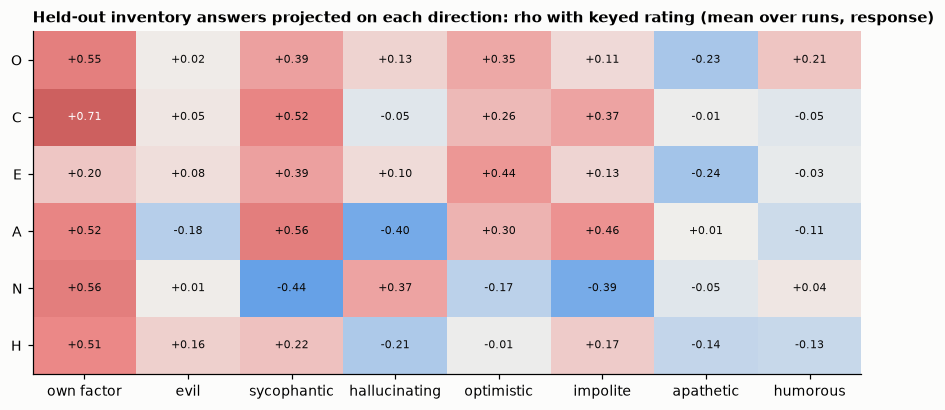

In [8]:
rows = []
for name in RUNS:
    layer = layer_of(LAYERS[name])
    traits, factors, agree = DIRS[name]
    X, raw, keyed = HEX[name]
    for f in FACTORS:
        x, y, _ = answers(X[:, :, layer], keyed, EVAL[f])
        if len(y) < 3:
            continue
        row = {"run": name, "factor": f, "answers": len(y),
               "own factor": hx.spearman(x @ factors[f], y) if f in factors else None}
        row |= {t: hx.spearman(x @ td, y) for t, td in traits.items()}
        rows.append(row)
TRANSFER = pd.DataFrame(rows)
TRANSFER.to_csv(OUT / "transfer.csv", index=False)
cols = ["own factor"] + TRAITS
mean_t = TRANSFER.groupby("factor")[[c for c in cols if c in TRANSFER]].mean().reindex(FACTORS)
print("rho with the held-out keyed ratings, mean over runs:\n")
show(mean_t, index=True)
best = mean_t[[t for t in TRAITS if t in mean_t]].abs().idxmax(axis=1)
print("\nbest trait readout per factor:", {f: f"{best[f]} ({mean_t.loc[f, best[f]]:+.2f} vs own {mean_t.loc[f, 'own factor']:+.2f})"
                                          for f in FACTORS if isinstance(best.get(f), str)})

fig, ax = plt.subplots(figsize=(0.75 * len(cols) + 2, 0.4 * len(FACTORS) + 1.4))
heat(ax, mean_t[[c for c in cols if c in mean_t]], 1.0)
ax.set_title(f"Held-out inventory answers projected on each direction: rho with keyed rating (mean over runs, {KIND})")
fig.tight_layout()
if SAVE_FIGS:
    fig.savefig(OUT / "5_transfer.png", bbox_inches="tight", dpi=150)
plt.show()

## 6. Which way do the differential prompts lean, in trait terms?

The prompt's direction: per item, the vector under a prompt minus under the baseline, averaged over items (all
136; no ratings are used). Its cosine with each trait direction says, for example, whether "take your time"
moves the state toward or away from `sycophantic`. Main effects are averaged over the other axis, as in
persona-hexaco-results section 4. A caution from there: the `prompt` kind has read different words, so a lean
can be lexical; `response` is less so.

In [9]:
COND_AT = {hx.levels(c): k for k, c in enumerate(CONDITIONS)}   # (DAN, INFO) -> condition index
EFFECTS = {"DAN0 - DAN1 (right away)": ("DAN", 0, 1), "DAN2 - DAN1 (take your time)": ("DAN", 2, 1),
           "INFO0 - INFO2 (HEXACO test)": ("INFO", 0, 2), "INFO1 - INFO2 (profiling)": ("INFO", 1, 2)}


def pairs_for(axis, level, ref):
    # (condition, reference condition) index pairs for one main effect, one per level of the other axis.
    keys = [((level, o), (ref, o)) if axis == "DAN" else ((o, level), (o, ref)) for o in range(3)]
    return [(COND_AT[a], COND_AT[b]) for a, b in keys if a in COND_AT and b in COND_AT]


rows = []
for name in RUNS:
    layer = layer_of(LAYERS[name])
    traits, factors, _ = DIRS[name]
    X = HEX[name][0][:, :, layer]
    for label, spec in EFFECTS.items():
        diffs = [np.nanmean(X[a] - X[b], axis=0) for a, b in pairs_for(*spec)]
        if not diffs:
            continue
        v = unit(np.mean(diffs, axis=0))
        rows.append({"run": name, "effect": label} | {t: float(v @ td) for t, td in traits.items()}
                    | {f"[{f}]": float(v @ fd) for f, fd in factors.items()})
LEAN = pd.DataFrame(rows)
LEAN.to_csv(OUT / "prompt_lean.csv", index=False)
print("cosine of each prompt effect with each trait direction (and, in brackets, each factor direction), mean over runs:\n")
show(LEAN.groupby("effect", sort=False)[[c for c in LEAN if c not in ("run", "effect")]].mean(), index=True)

cosine of each prompt effect with each trait direction (and, in brackets, each factor direction), mean over runs:

                              evil  hallucinating  sycophantic  apathetic  humorous  impolite  optimistic   [O]   [C]   [E]   [A]   [N]   [H]
effect                                                                                                                                       
DAN0 - DAN1 (right away)     +0.05          +0.03        +0.03      +0.14     +0.03     +0.12       -0.04 +0.13 -0.03 +0.15 -0.10 +0.08 +0.00
DAN2 - DAN1 (take your time) -0.02          +0.12        +0.04      -0.12     +0.01     -0.02       -0.02 -0.13 +0.00 -0.17 +0.12 +0.02 +0.01
INFO0 - INFO2 (HEXACO test)  -0.02          +0.01        -0.03      -0.02     +0.02     +0.02       -0.04 -0.14 +0.07 -0.03 +0.09 +0.01 +0.01
INFO1 - INFO2 (profiling)    -0.02          -0.00        -0.02      +0.01     +0.01     -0.01       -0.00 +0.03 -0.11 +0.28 -0.20 +0.15 -0.12


## 7. RP-LSH: does the cross-reference survive hashing?

Each direction is hashed with `RandomProjectionBackend` at each size in `RP_BITS`, with the model's own seed
from section 1 and `REPLICATES` consecutive plusRand offsets (independent projections). The cosine is estimated
from the normalized Hamming distance h as cos(pi h). Reported per size: the mean absolute error against the exact
cosine over all trait-by-factor cells, the share of cells with the same sign, and the share of the cells beyond
the null (p < `ALPHA`) whose sign survives. The spread over replicates says how much the result depends on the hyperplanes drawn.

The expected error is set by the bits, not the model: the SD of the estimate near cosine 0 is about
pi x sqrt(1/(4n)), 0.098 at 256 bits and 0.049 at 1024 (mean absolute error about 0.8 of that). Cosines below that are below the digest's resolution.

In [10]:
rows = []
for name in RUNS:
    traits, factors, _ = DIRS[name]
    dim = next(iter(traits.values())).shape[0]
    exact = COS[(COS["run"] == name) & (COS["factor"] != "agree")].set_index(["trait", "factor"])
    for bits in RP_BITS:
        for k, s in enumerate(lsh_seed.replicate_seeds(SEEDS[name]["seed"], REPLICATES)):
            h = RandomProjectionBackend(dim=dim, n_bits=bits, seed=s)
            dt = {t: h.hash_vector(v) for t, v in traits.items()}
            df = {f: h.hash_vector(v) for f, v in factors.items()}
            est = pd.Series({(t, f): np.cos(np.pi * h.distance(dt[t], df[f])) for t in dt for f in df})
            ex = exact.loc[est.index, "cosine"]
            sig = exact.loc[est.index, "p"] < ALPHA
            rows.append({"run": name, "bits": bits, "replicate": k, "seed": s,
                         "mean abs error": float((est - ex).abs().mean()),
                         "same sign": float((np.sign(est) == np.sign(ex)).mean()),
                         "sig cells kept": float((np.sign(est[sig]) == np.sign(ex[sig])).mean()) if sig.any() else np.nan})
RP = pd.DataFrame(rows)
RP.to_csv(OUT / "rp_lsh.csv", index=False)
summary = RP.groupby(["run", "bits"]).agg(err=("mean abs error", "mean"), err_sd=("mean abs error", "std"),
                                          same_sign=("same sign", "mean"), sig_kept=("sig cells kept", "mean")).reset_index()
show(summary)
for bits in RP_BITS:
    print(f"expected SD near 0 at {bits} bits: {np.pi * np.sqrt(1 / (4 * bits)):.3f}")

             run  bits   err  err_sd  same_sign  sig_kept
        bolt-e4b   256 +0.08   +0.01      +0.62       NaN
        bolt-e4b  1024 +0.04   +0.01      +0.79       NaN
   granite4.2-8b   256 +0.08   +0.02      +0.70       NaN
   granite4.2-8b  1024 +0.04   +0.01      +0.87       NaN
     llama3.1-8b   256 +0.08   +0.02      +0.66       NaN
     llama3.1-8b  1024 +0.04   +0.01      +0.70       NaN
nemotron-nano-8b   256 +0.06   +0.02      +0.62       NaN
nemotron-nano-8b  1024 +0.03   +0.01      +0.70       NaN
        qwen3-8b   256 +0.07   +0.01      +0.62       NaN
        qwen3-8b  1024 +0.04   +0.01      +0.70       NaN
expected SD near 0 at 256 bits: 0.049
expected SD near 0 at 1024 bits: 0.025


## 8. Layer sweep

Sections 2 and 3 at every layer (cosine only, no null, to keep it quick): the mean |cosine| over all
trait-by-factor cells, and the share of prior cells with the expected sign. Depth is layer / layers so models of
different depth line up; the dashed line is the default depth.

             run  best layer (priors)  depth  prior signs ok there  at default
        bolt-e4b                    6  +0.14                 +0.73       +0.55
   granite4.2-8b                   16  +0.40                 +0.78       +0.56
     llama3.1-8b                   32  +1.00                 +0.82       +0.64
nemotron-nano-8b                   16  +0.50                 +0.83       +0.33
        qwen3-8b                   14  +0.39                 +0.82       +0.55


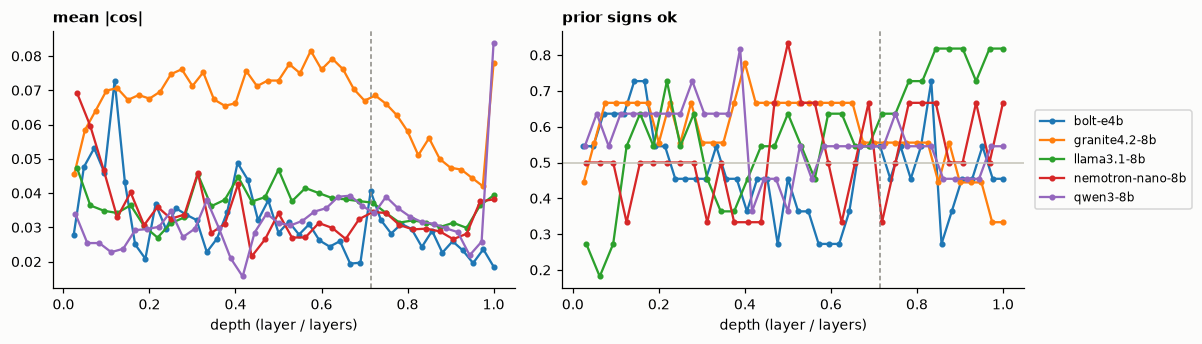

In [11]:
curves, rows = {}, []
for name in RUNS:
    curve = []
    for layer in range(1, LAYERS[name] + 1):
        traits, factors, _ = directions_at(name, layer)
        cells = [(t, f, float(traits[t] @ factors[f])) for t in traits for f in factors]
        prior = [np.sign(c) == PRIORS[(t, f)] for t, f, c in cells if (t, f) in PRIORS]
        curve.append({"layer": layer, "depth": layer / LAYERS[name], "mean |cos|": np.mean([abs(c) for *_, c in cells]),
                      "prior signs ok": np.mean(prior) if prior else np.nan})
    curves[name] = curve
    best = max(curve, key=lambda c: (np.nan_to_num(c["prior signs ok"]), c["mean |cos|"]))
    rows.append({"run": name, "best layer (priors)": best["layer"], "depth": best["depth"],
                 "prior signs ok there": best["prior signs ok"],
                 "at default": curve[layer_of(LAYERS[name]) - 1]["prior signs ok"]})
show(pd.DataFrame(rows))
(OUT / "layer_curves.json").write_text(json.dumps(curves, indent=1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for name in RUNS:
    for ax, key in zip(axes, ("mean |cos|", "prior signs ok")):
        ax.plot([c["depth"] for c in curves[name]], [c[key] for c in curves[name]], marker="o", markersize=3, label=name)
for ax, key in zip(axes, ("mean |cos|", "prior signs ok")):
    ax.axvline(LAYER_DEPTH, color="#898781", linestyle=(0, (3, 2)), linewidth=1)
    ax.set_title(key)
    ax.set_xlabel("depth (layer / layers)")
axes[1].axhline(0.5, color="#c3c2b7", linewidth=1)
axes[1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
if SAVE_FIGS:
    fig.savefig(OUT / "8_layer_sweep.png", bbox_inches="tight", dpi=150)
plt.show()

## What to read off

1. **Section 2**: which trait-by-factor cells beat the permutation null, and whether `agree` is as large as the
   factors (then the trait lines up with "agreeing", not with a factor; persona-hexaco-results section 7 found
   the factor directions largely share one axis, leakage 0.5-1.0).
2. **Section 3**: the prior cells' sign agreement and its sign-test p. evil-H and evil-A are the headline pair.
3. **Section 4**: whether the pattern is shared across models (it decides whether one cross-reference table can
   serve every model).
4. **Section 5**: the best trait readout of each factor against the factor's own direction.
5. **Section 6**: whether "take your time" or "HEXACO test" moves the state toward sycophantic or away from evil.
6. **Section 7**: whether 256 bits resolve the significant cells, or whether this needs 1024.
7. **Section 8**: whether the cross-reference peaks where persona-lsh's persona signal did (59-80% of depth).

Limits: one HEXACO split and one persona-lsh draw; the two experiments' contexts differ (persona-lsh replies are
120-token answers to open questions under a persona system prompt, HEXACO replies are short Likert answers with
no system prompt), so a cosine near 0 can mean different contexts rather than unrelated traits.